In [1]:
# AED por UF: caracterização estadual de instâncias que continuam municipais.
from pathlib import Path
import pandas as pd
import numpy as np
import pyogrio
import matplotlib.pyplot as plt

In [ ]:
# Caminhos válidos ao executar pela raiz do projeto ou por src/.
raiz_projeto = Path.cwd()
if raiz_projeto.name == "src":
    raiz_projeto = raiz_projeto.parent

# Troque a UF e reinicie o kernel: MG 31 | SP 35 | DF 53.
codigo_uf = "31"
arquivo_uf = raiz_projeto / "data" / "BR_setores_CD2022.gpkg"
pasta_outputs = raiz_projeto / "outputs" / "uf" / codigo_uf
pasta_outputs.mkdir(parents=True, exist_ok=True)

print("Arquivo encontrado:", arquivo_uf.exists())


In [ ]:
colunas = [
    "CD_SETOR", "CD_MUN", "NM_MUN", "CD_UF", "NM_UF",
    "SITUACAO", "CD_SIT", "CD_TIPO", "AREA_KM2", "v0001",
]
uf_registros = pyogrio.read_dataframe(
    arquivo_uf, layer="BR_setores_CD2022", columns=colunas,
    where=f"CD_UF = '{codigo_uf}'", read_geometry=False,
)
if uf_registros.empty:
    raise ValueError("UF não encontrada no arquivo.")
nome_uf = uf_registros["NM_UF"].iloc[0]
print("UF selecionada:", nome_uf)
uf_registros.head()

UF selecionada: Minas Gerais


,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_UF,NM_UF,CD_MUN,NM_MUN,v0001
0,310010405000001,Urbana,1,0,0.270934,31,Minas Gerais,3100104,Abadia dos Dourados,458
1,310010405000002,Urbana,1,0,0.176252,31,Minas Gerais,3100104,Abadia dos Dourados,220
2,310010405000003,Urbana,1,0,0.138859,31,Minas Gerais,3100104,Abadia dos Dourados,373
3,310010405000004,Urbana,1,0,0.224741,31,Minas Gerais,3100104,Abadia dos Dourados,440
4,310010405000005,Urbana,1,0,0.111173,31,Minas Gerais,3100104,Abadia dos Dourados,398


In [ ]:
resumo_registros = pd.Series({
    "Registros originais": len(uf_registros),
    "Códigos de setor distintos": uf_registros["CD_SETOR"].nunique(),
    "Repetições além da primeira": uf_registros["CD_SETOR"].duplicated().sum(),
})

resumo_registros

Registros originais            51392
Códigos de setor distintos     51387
Repetições além da primeira        5
dtype: int64

In [ ]:
# Uma linha por conjunto de atributos, sem modificar o arquivo original.
uf = uf_registros.drop_duplicates().copy()
conflitos = uf.loc[uf["CD_SETOR"].duplicated(keep=False)]

print("Setores com atributos conflitantes:", conflitos["CD_SETOR"].nunique())
if not conflitos.empty:
    raise ValueError("Investigar atributos conflitantes antes de agregar a população.")

Setores com atributos conflitantes: 0


In [ ]:
uf["populacao"] = uf["v0001"]
uf["codigo_setor_ausente"] = uf["CD_SETOR"].fillna("").str.strip().eq("")
uf["codigo_municipio_ausente"] = uf["CD_MUN"].fillna("").str.strip().eq("")
uf["codigo_uf_ausente"] = uf["CD_UF"].fillna("").str.strip().eq("")
uf["area_inadequada"] = uf["AREA_KM2"].isna() | uf["AREA_KM2"].le(0)
uf["populacao_inadequada"] = (
    uf["populacao"].isna() | uf["populacao"].lt(0) | uf["populacao"].mod(1).ne(0)
)

In [ ]:
colunas_qualidade = [
    "codigo_setor_ausente", "codigo_municipio_ausente", "codigo_uf_ausente",
    "area_inadequada", "populacao_inadequada",
]
qualidade_uf = uf[colunas_qualidade].sum().rename("setores_com_ocorrencia")

qualidade_uf

codigo_setor_ausente        0
codigo_municipio_ausente    0
codigo_uf_ausente           0
area_inadequada             0
populacao_inadequada        0
Name: setores_com_ocorrencia, dtype: int64

In [ ]:
# Descrições de situação e tipo vêm do dicionário da malha.
dicionario = pd.read_excel(raiz_projeto / "data" / "Dicionario_de_dados_malha_agregados.xlsx")
dicionario.columns = ["variavel", "codigo", "descricao"]
dicionario["variavel"] = dicionario["variavel"].ffill()
dicionario["codigo"] = dicionario["codigo"].astype("string").str.replace(r"\.0$", "", regex=True).str.strip()

In [ ]:
mapa_situacao = dicionario.loc[
    dicionario["variavel"].eq("CD_SITUACAO") & dicionario["codigo"].notna()
].set_index("codigo")["descricao"]
mapa_tipo = dicionario.loc[
    dicionario["variavel"].eq("CD_TIPO") & dicionario["codigo"].notna()
].set_index("codigo")["descricao"]

In [ ]:
uf["descricao_situacao"] = uf["CD_SIT"].map(mapa_situacao).fillna("Código não descrito ou ausente")
uf["descricao_tipo"] = uf["CD_TIPO"].map(mapa_tipo).fillna("Código não descrito ou ausente")
uf["densidade_hab_km2"] = uf["populacao"] / uf["AREA_KM2"].where(uf["AREA_KM2"].gt(0))

codigos_nao_descritos = pd.Series({
    "CD_SIT": uf.loc[~uf["CD_SIT"].isin(mapa_situacao.index), "CD_SIT"].unique().tolist(),
    "CD_TIPO": uf.loc[~uf["CD_TIPO"].isin(mapa_tipo.index), "CD_TIPO"].unique().tolist(),
})
codigos_nao_descritos

CD_SIT     []
CD_TIPO    []
dtype: object

In [ ]:
# Confirmação do que fica fora do recorte antes de construir as instâncias.
uf["situacao_analise"] = uf["SITUACAO"].copy()
uf.loc[uf["CD_SIT"].eq("9"), "situacao_analise"] = "Massas de água"

resumo_classificacao = uf.groupby("situacao_analise", dropna=False).agg(
    setores=("CD_SETOR", "count"), populacao=("populacao", "sum"),
)
resumo_classificacao

,setores,populacao
situacao_analise,,
Massas de água,64,0
Rural,11525,2418095
Urbana,39798,18121894


In [ ]:
# O recorte inclui urbanos e rurais, todos os tipos e setores de população zero.
uf_analise = uf.loc[uf["situacao_analise"].isin(["Urbana", "Rural"])].copy()
fora_recorte = uf.loc[~uf["situacao_analise"].isin(["Urbana", "Rural"])]

print("Setores urbanos e rurais:", len(uf_analise))
print("População fora do recorte:", fora_recorte["populacao"].sum())

Setores urbanos e rurais: 51323
População fora do recorte: 0


In [ ]:
# Comparação urbano/rural: densidade do grupo e mediana dos setores são distintas.
resumo_territorial = uf_analise.groupby("situacao_analise").agg(
    setores=("CD_SETOR", "count"),
    populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    area_mediana_setor_km2=("AREA_KM2", "median"),
    densidade_mediana_setor=("densidade_hab_km2", "median"),
)
resumo_territorial["densidade_grupo"] = resumo_territorial["populacao"] / resumo_territorial["area_km2"]
resumo_territorial["populacao_percentual"] = 100 * resumo_territorial["populacao"] / uf_analise["populacao"].sum()
resumo_territorial.round(2)

,setores,populacao,area_km2,area_mediana_setor_km2,densidade_mediana_setor,densidade_grupo,populacao_percentual
situacao_analise,,,,,,,
Rural,11525,2418095,575534.34,30.41,6.48,4.20,11.77
Urbana,39798,18121894,9341.44,0.09,4921.74,1939.95,88.23


In [ ]:
# CD_SIT descreve o território. Inclui os setores fora do recorte urbano e rural.
resumo_situacao = uf.groupby(["CD_SIT", "descricao_situacao"], dropna=False).agg(
    setores=("CD_SETOR", "count"), populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    densidade_mediana_setor=("densidade_hab_km2", "median"),
)
resumo_situacao.round(2)

,,setores,populacao,area_km2,densidade_mediana_setor
CD_SIT,descricao_situacao,,,,
1,Área urbana de alta densidade de edificações de cidade ou vila,35973,17045305,5351.67,5467.71
2,Área urbana de baixa densidade de edificações de cidade ou vila,2779,754423,3287.45,279.39
3,Núcleo urbano,1046,322166,702.32,745.55
5,Aglomerado rural - Povoado,939,191202,536.08,564.18
6,Aglomerado rural - Núcleo rural,16,1121,13.79,72.15
7,Aglomerado rural - Lugarejo,256,24927,201.41,160.23
8,Área rural (exclusive aglomerados),10314,2200845,574783.06,5.41
9,Massas de água,64,0,1638.20,0.00


In [ ]:
# CD_TIPO caracteriza a ocupação, sem excluir setores institucionais.
resumo_tipos = uf_analise.groupby(["CD_TIPO", "descricao_tipo"], dropna=False).agg(
    setores=("CD_SETOR", "count"), populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    populacao_mediana_setor=("populacao", "median"),
    densidade_mediana_setor=("densidade_hab_km2", "median"),
)
resumo_tipos["populacao_percentual"] = 100 * resumo_tipos["populacao"] / uf_analise["populacao"].sum()
resumo_tipos.round(2)

,,setores,populacao,area_km2,populacao_mediana_setor,densidade_mediana_setor,populacao_percentual
CD_TIPO,descricao_tipo,,,,,,
0,Não especial,48144,19674842,582786.45,397.0,3217.84,95.79
1,Favela e Comunidade Urbana,1691,739932,107.11,427.0,13151.57,3.60
2,Quartel e base militar,11,1702,8.02,32.0,119.53,0.01
3,Alojamento / acampamento,4,257,1.66,59.0,1029.21,0.00
4,Setor com baixo patamar domiciliar,583,3411,1487.49,0.0,0.00,0.02
5,Agrupamento indígena,74,11442,49.07,81.0,279.38,0.06
6,Unidade prisional,134,37280,4.86,128.5,18647.65,0.18
7,Convento / hospital / ILPI / IACA,136,7906,18.12,55.0,6865.92,0.04
8,Agrovila do PA,4,838,2.51,208.5,352.53,0.00


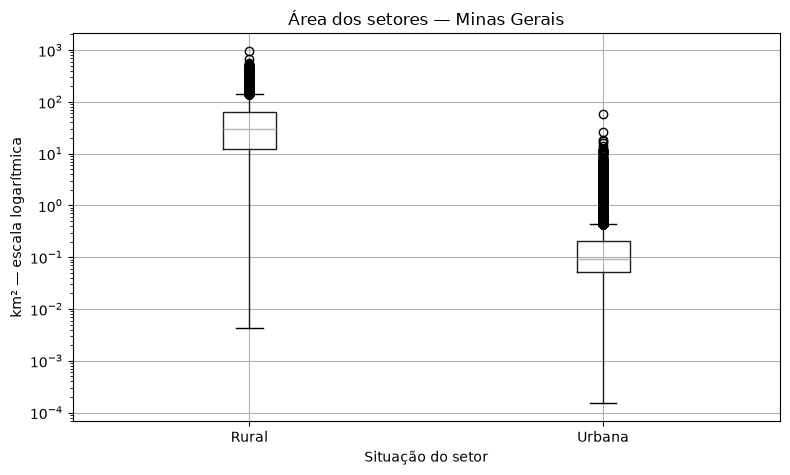

In [ ]:
# Valores zero permanecem nas tabelas, mas não aparecem na escala logarítmica.
dados_positivos = uf_analise.loc[uf_analise["AREA_KM2"].gt(0)]
fig, ax = plt.subplots(figsize=(8, 5))
dados_positivos.boxplot(column="AREA_KM2", by="situacao_analise", ax=ax)
ax.set_yscale("log")
ax.set_title(f"Área dos setores — {nome_uf}")
ax.set_xlabel("Situação do setor")
ax.set_ylabel("km² — escala logarítmica")
fig.suptitle("")
plt.tight_layout()
fig.savefig(pasta_outputs / "area_setores.svg", bbox_inches="tight")
plt.show()

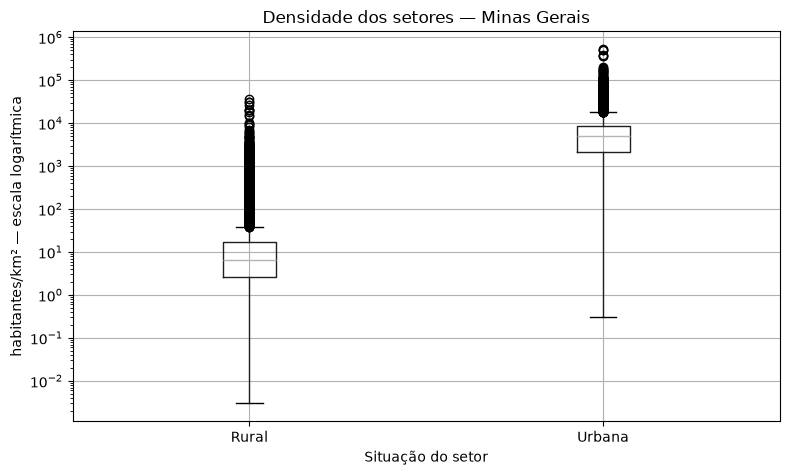

In [17]:
# Valores zero permanecem nas tabelas, mas não aparecem na escala logarítmica.
dados_positivos = uf_analise.loc[uf_analise["densidade_hab_km2"].gt(0)]
fig, ax = plt.subplots(figsize=(8, 5))
dados_positivos.boxplot(column="densidade_hab_km2", by="situacao_analise", ax=ax)
ax.set_yscale("log")
ax.set_title(f"Densidade dos setores — {nome_uf}")
ax.set_xlabel("Situação do setor")
ax.set_ylabel("habitantes/km² — escala logarítmica")
fig.suptitle("")
plt.tight_layout()
fig.savefig(pasta_outputs / "densidade_setores.svg", bbox_inches="tight")
plt.show()


In [ ]:
# Candidatos incluem setores urbanos e rurais sem população. Demanda positiva é separada.
uf_analise["demanda_positiva"] = uf_analise["populacao"].gt(0)
uf_analise["populacao_rural"] = uf_analise["populacao"].where(
    uf_analise["situacao_analise"].eq("Rural"), 0,
)
uf_analise["area_rural_km2"] = uf_analise["AREA_KM2"].where(
    uf_analise["situacao_analise"].eq("Rural"), 0,
)

In [ ]:
# Códigos identificam os recortes. Nomes podem se repetir no país.
resumo_municipios = uf_analise.groupby(
    ["CD_UF", "CD_MUN", "NM_MUN"], dropna=False,
).agg(
    setores=("CD_SETOR", "count"),
    origens_demanda_positiva=("demanda_positiva", "sum"),
    populacao=("populacao", "sum"),
    area_km2=("AREA_KM2", "sum"),
    populacao_rural=("populacao_rural", "sum"),
    area_rural_km2=("area_rural_km2", "sum"),
)

In [ ]:
# Participações rurais descrevem população e território, separadamente.
resumo_municipios["populacao_rural_percentual"] = (
    100 * resumo_municipios["populacao_rural"] / resumo_municipios["populacao"].where(resumo_municipios["populacao"].gt(0))
)
resumo_municipios["area_rural_percentual"] = (
    100 * resumo_municipios["area_rural_km2"] / resumo_municipios["area_km2"]
)
resumo_municipios["densidade_hab_km2"] = resumo_municipios["populacao"] / resumo_municipios["area_km2"]

resumo_municipios.head().round(2)

setores  origens_demanda_positiva  \
CD_UF CD_MUN  NM_MUN                                                   
31    3100104 Abadia dos Dourados       19                        19   
      3100203 Abaeté                    71                        71   
      3100302 Abre Campo                36                        36   
      3100401 Acaiaca                   20                        20   
      3100500 Açucena                   38                        38   

                                   populacao  area_km2  populacao_rural  \
CD_UF CD_MUN  NM_MUN                                                      
31    3100104 Abadia dos Dourados       6272    880.46             1880   
      3100203 Abaeté                   22675   1817.07             2415   
      3100302 Abre Campo               13927    470.55             5432   
      3100401 Acaiaca                   3909    101.89             1075   
      3100500 Açucena                   8943    815.42             4422   

                                   area_rural_km2  populacao_rural_percentual  \
CD_UF CD_MUN  NM_MUN                                                            
31    3100104 Abadia dos Dourados          877.70                       29.97   
      3100203 Abaeté                      1803.30                       10.65   
      3100302 Abre Campo                   463.89                       39.00   
      3100401 Acaiaca                       99.58                       27.50   
      3100500 Açucena                      810.13                       49.45   

                                   area_rural_percentual  densidade_hab_km2  
CD_UF CD_MUN  NM_MUN                                                         
31    3100104 Abadia dos Dourados                  99.69               7.12  
      3100203 Abaeté                               99.24              12.48  
      3100302 Abre Campo                           98.58              29.60  
      3100401 Acaiaca                              97.73              38.37  
      3100500 Açucena                              99.35              10.97

In [ ]:
# n² é a previsão com todos os setores urbanos e rurais como origens e candidatos.
# Zero demanda pode ser omitida na modelagem. Não removi esses candidatos.
resumo_municipios["pares_distancias"] = resumo_municipios["setores"] ** 2
resumo_municipios["memoria_matriz_gib"] = resumo_municipios["pares_distancias"] * 8 / 1024 ** 3

resumo_municipios.nlargest(10, "setores").round(2)

setores  origens_demanda_positiva  \
CD_UF CD_MUN  NM_MUN                                                    
31    3106200 Belo Horizonte           5166                      5137   
      3170206 Uberlândia               1988                      1924   
      3118601 Contagem                 1311                      1305   
      3136702 Juiz de Fora             1191                      1166   
      3106705 Betim                     978                       969   
      3170107 Uberaba                   896                       865   
      3143302 Montes Claros             884                       864   
      3154606 Ribeirão das Neves        621                       614   
      3167202 Sete Lagoas               572                       571   
      3127701 Governador Valadares      560                       550   

                                    populacao  area_km2  populacao_rural  \
CD_UF CD_MUN  NM_MUN                                                       
31    3106200 Belo Horizonte          2315560    331.35                0   
      3170206 Uberlândia               713224   4115.21            10026   
      3118601 Contagem                 621863    192.05              847   
      3136702 Juiz de Fora             540756   1435.75             6006   
      3106705 Betim                    411846    343.65             1897   
      3170107 Uberaba                  337836   4491.09             7474   
      3143302 Montes Claros            414240   3589.52            16814   
      3154606 Ribeirão das Neves       329794    155.10             3002   
      3167202 Sete Lagoas              227397    536.33             7464   
      3127701 Governador Valadares     257171   2342.38             8247   

                                    area_rural_km2  \
CD_UF CD_MUN  NM_MUN                                 
31    3106200 Belo Horizonte                  0.00   
      3170206 Uberlândia                   3873.77   
      3118601 Contagem                       43.19   
      3136702 Juiz de Fora                 1121.61   
      3106705 Betim                         130.93   
      3170107 Uberaba                      4301.65   
      3143302 Montes Claros                3482.61   
      3154606 Ribeirão das Neves             63.20   
      3167202 Sete Lagoas                   463.37   
      3127701 Governador Valadares         2258.53   

                                    populacao_rural_percentual  \
CD_UF CD_MUN  NM_MUN                                             
31    3106200 Belo Horizonte                              0.00   
      3170206 Uberlândia                                  1.41   
      3118601 Contagem                                    0.14   
      3136702 Juiz de Fora                                1.11   
      3106705 Betim                                       0.46   
      3170107 Uberaba                                     2.21   
      3143302 Montes Claros                               4.06   
      3154606 Ribeirão das Neves                          0.91   
      3167202 Sete Lagoas                                 3.28   
      3127701 Governador Valadares                        3.21   

                                    area_rural_percentual  densidade_hab_km2  \
CD_UF CD_MUN  NM_MUN                                                           
31    3106200 Belo Horizonte                         0.00            6988.18   
      3170206 Uberlândia                            94.13             173.31   
      3118601 Contagem                              22.49            3237.95   
      3136702 Juiz de Fora                          78.12             376.64   
      3106705 Betim                                 38.10            1198.45   
      3170107 Uberaba                               95.78              75.22   
      3143302 Montes Claros                         97.02             115.40   
      3154606 Ribeirão das Neves                    40.75            2126.27   
    

In [22]:
# Distribuição dos tamanhos municipais, e não de uma instância estadual única.
resumo_municipios["setores"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])

count     853.000000
mean       60.167644
std       213.727403
min         3.000000
25%        15.000000
50%        25.000000
75%        47.000000
90%        98.000000
95%       207.400000
max      5166.000000
Name: setores, dtype: float64

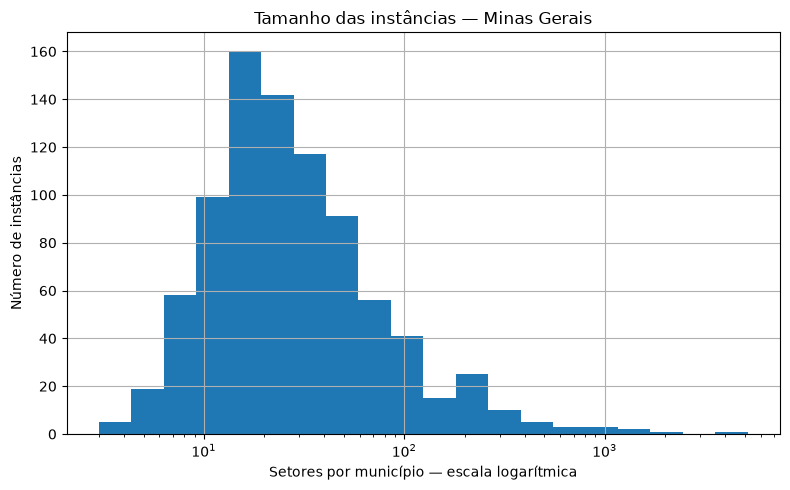

In [23]:
# Faixas logarítmicas quando há municípios de tamanhos diferentes.
tamanhos = resumo_municipios["setores"]
fig, ax = plt.subplots(figsize=(8, 5))
if tamanhos.min() < tamanhos.max():
    faixas = np.geomspace(tamanhos.min(), tamanhos.max() + 1, 21)
    tamanhos.hist(bins=faixas, ax=ax)
    ax.set_xscale("log")
    ax.set_xlabel("Setores por município — escala logarítmica")
else:
    ax.bar([tamanhos.iloc[0]], [len(tamanhos)], width=max(1, tamanhos.iloc[0] * 0.05))
    ax.set_xlabel("Setores por recorte")
ax.set_ylabel("Número de instâncias")
ax.set_title(f"Tamanho das instâncias — {nome_uf}")
plt.tight_layout()
fig.savefig(pasta_outputs / "tamanho_instancias.svg", bbox_inches="tight")
plt.show()


In [ ]:
# Os maiores municípios ajudam a identificar futuros testes de escala.
maiores_instancias = resumo_municipios.nlargest(20, "setores")
maiores_instancias.round(2)

setores  origens_demanda_positiva  \
CD_UF CD_MUN  NM_MUN                                                    
31    3106200 Belo Horizonte           5166                      5137   
      3170206 Uberlândia               1988                      1924   
      3118601 Contagem                 1311                      1305   
      3136702 Juiz de Fora             1191                      1166   
      3106705 Betim                     978                       969   
      3170107 Uberaba                   896                       865   
      3143302 Montes Claros             884                       864   
      3154606 Ribeirão das Neves        621                       614   
      3167202 Sete Lagoas               572                       571   
      3127701 Governador Valadares      560                       550   
      3122306 Divinópolis               548                       542   
      3131307 Ipatinga                  464                       456   
      3148004 Patos de Minas            426                       426   
      3157807 Santa Luzia               398                       398   
      3151800 Poços de Caldas           384                       384   
      3129806 Ibirité                   342                       339   
      3152501 Pouso Alegre              331                       330   
      3147907 Passos                    325                       324   
      3171204 Vespasiano                325                       323   
      3156700 Sabará                    309                       307   

                                    populacao  area_km2  populacao_rural  \
CD_UF CD_MUN  NM_MUN                                                       
31    3106200 Belo Horizonte          2315560    331.35                0   
      3170206 Uberlândia               713224   4115.21            10026   
      3118601 Contagem                 621863    192.05              847   
      3136702 Juiz de Fora             540756   1435.75             6006   
      3106705 Betim                    411846    343.65             1897   
      3170107 Uberaba                  337836   4491.09             7474   
      3143302 Montes Claros            414240   3589.52            16814   
      3154606 Ribeirão das Neves       329794    155.10             3002   
      3167202 Sete Lagoas              227397    536.33             7464   
      3127701 Governador Valadares     257171   2342.38             8247   
      3122306 Divinópolis              231091    708.11             5611   
      3131307 Ipatinga                 227731    164.88              603   
      3148004 Patos de Minas           159235   3190.46             9887   
      3157807 Santa Luzia              219132    235.20             2571   
      3151800 Poços de Caldas          163742    539.82             3648   
      3129806 Ibirité                  170537     72.39              438   
      3152501 Pouso Alegre             152217    542.80            12609   
      3147907 Passos                   111939   1338.07             4526   
      3171204 Vespasiano               129246     71.04              868   
      3156700 Sabará                   129380    302.45             1571   

                                    area_rural_km2  \
CD_UF CD_MUN  NM_MUN                                 
31    3106200 Belo Horizonte                  0.00   
      3170206 Uberlândia                   3873.77   
      3118601 Contagem                       43.19   
      3136702 Juiz de Fora                 1121.61   
      3106705 Betim                         130.93   
      3170107 Uberaba                      4301.65   
      3143302 Montes Claros                3482.61   
      3154606 Ribeirão das Neves             63.20   
      3167202 Sete Lagoas                   463.37   
      3127701 Governador Valadares         2258.53   
      3122306 Divinópolis                   565.54   
      3131307 Ipatinga                       80.96   


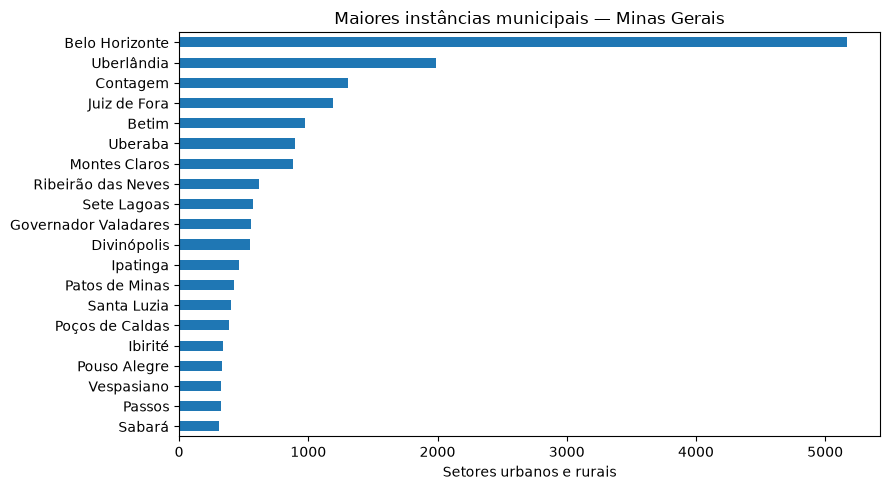

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
maiores_instancias.sort_values("setores").reset_index().plot.barh(
    x="NM_MUN", y="setores", ax=ax, legend=False,
)
ax.set_title(f"Maiores instâncias municipais — {nome_uf}")
ax.set_xlabel("Setores urbanos e rurais")
ax.set_ylabel("")
plt.tight_layout()
fig.savefig(pasta_outputs / "maiores_instancias.svg", bbox_inches="tight")
plt.show()

In [ ]:
# População concentrada nos maiores municípios, sem pressupor dispersão pela UF.
concentracao = pd.Series({
    "Maior município (%)": 100 * resumo_municipios["populacao"].max() / resumo_municipios["populacao"].sum(),
    "Até cinco maiores municípios (%)": 100 * resumo_municipios["populacao"].nlargest(5).sum() / resumo_municipios["populacao"].sum(),
})
concentracao.round(2)

Maior município (%)                 11.27
Até cinco maiores municípios (%)    22.42
dtype: float64

In [ ]:
# Pendências de atributos por município, incluindo setores fora do recorte urbano e rural.
uf["atributos_com_pendencia"] = uf[colunas_qualidade].any(axis=1)
pendencias_municipais = uf.groupby(["CD_MUN", "NM_MUN"], dropna=False)["atributos_com_pendencia"].sum()
pendencias_municipais.loc[pendencias_municipais.gt(0)]

Series([], Name: atributos_com_pendencia, dtype: int64)

In [ ]:
# Síntese da UF para comparação no relatório.
resumo_uf = pd.Series({
    "Codigo_UF": codigo_uf, "Nome_UF": nome_uf, "Ano": 2022,
    "Instancias": len(resumo_municipios),
    "Setores_urbanos_rurais": len(uf_analise),
    "Populacao": uf_analise["populacao"].sum(),
    "Mediana_setores_instancia": resumo_municipios["setores"].median(),
    "P90_setores_instancia": resumo_municipios["setores"].quantile(0.90),
    "Maior_instancia_setores": resumo_municipios["setores"].max(),
    "Municipios_com_pendencias": pendencias_municipais.gt(0).sum(),
})
resumo_uf

Codigo_UF                              31
Nome_UF                      Minas Gerais
Ano                                  2022
Instancias                            853
Setores_urbanos_rurais              51323
Populacao                        20539989
Mediana_setores_instancia            25.0
P90_setores_instancia                98.0
Maior_instancia_setores              5166
Municipios_com_pendencias               0
dtype: object

In [ ]:
# Síntese.
resumo_uf.to_json(pasta_outputs / "resumo_uf.json", force_ascii=False, indent=2)
print("Síntese e figuras em:", pasta_outputs.resolve())

Síntese e figuras em: /home/jz/PM/outputs/uf/31
